# 02. EDA признаков

**Цель:** проверить свойства признаков, найти различающие ПТСР и Норму, оценить возрастной конфаундер.

In [8]:
# Setup
import os
from pathlib import Path
os.chdir(r"C:\Users\Home\Desktop\PTSD EEG")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr, pearsonr

FIG_DIR = Path("results/figures")
sns.set_style("whitegrid")

df = pd.read_csv("data/features_subject.csv")
print("Форма таблицы признаков:", df.shape)
print("Группы:", df.groupby("group").size().to_dict())

Форма таблицы признаков: (164, 741)
Группы: {'Норма': 67, 'ПТСР': 25, 'Соматоформные': 72}


## Проверка 1 ТЗ: возраст в признаках

**Цель:** убедиться, что ЭЭГ-признаки не являются возрастными маркерами. Если модель будет использовать возрастной сигнал — она может разделять группы по возрасту, а не по ПТСР.

**Метод:** обучаем Ridge-регрессию для предсказания возраста по всем 741 признаку внутри контрольной группы (n=67, возраст 19–58 лет), 5-fold кросс-валидация.

**Критерий:** если R² высокий или Spearman ρ значим — признаки несут возрастной сигнал.

In [9]:
# Проверка 1 ТЗ: возраст в признаках
from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_predict, KFold
from sklearn.metrics import r2_score

control = df[df["group"] == "Норма"].copy()
feature_cols = [c for c in df.columns if c not in ["subject_id", "group", "age"]]

X_age = control[feature_cols].values
y_age = control["age"].values

pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("model", RidgeCV(alphas=[0.1, 1, 10, 100])),
])
kf = KFold(n_splits=5, shuffle=True, random_state=42)
age_pred = cross_val_predict(pipe, X_age, y_age, cv=kf)

r2 = r2_score(y_age, age_pred)
rho, p_rho = spearmanr(y_age, age_pred)
r, p_r = pearsonr(y_age, age_pred)

print("=" * 60)
print("ПРОВЕРКА 1 ТЗ: возраст внутри контроля")
print("=" * 60)
print(f"R² = {r2:.3f}")
print(f"Spearman ρ = {rho:.3f} (p={p_rho:.3f})")
print(f"Pearson r = {r:.3f} (p={p_r:.3f})")
print("\nИнтерпретация: |ρ| < 0.2, R² < 0 → возрастного сигнала в признаках нет")

ПРОВЕРКА 1 ТЗ: возраст внутри контроля
R² = -0.369
Spearman ρ = -0.028 (p=0.823)
Pearson r = 0.042 (p=0.737)

Интерпретация: |ρ| < 0.2, R² < 0 → возрастного сигнала в признаках нет


### Результат

| Метрика | Значение | p-value |
|---|---|---|
| R² (CV) | **−0.369** | — |
| Spearman ρ | **−0.028** | 0.823 |
| Pearson r | 0.042 | 0.737 |

**Интерпретация:**
- Отрицательный R² означает, что модель предсказывает возраст **хуже константного среднего** — в признаках нет линейного сигнала о возрасте.
- Spearman ρ ≈ 0 и Pearson r ≈ 0, оба **не значимы** (p > 0.7).
- **Вывод:** возрастной сигнал в признаках **отсутствует**. Возрастной конфаундер на уровне признаков **исключён**.

## Топ-признаки, различающие ПТСР и Норму

Для каждого из 741 признака считаем непараметрический тест Mann-Whitney U (ПТСР vs Норма) и величину эффекта **Cliff's delta** — робастный аналог d Коэна.

**Интерпретация |Cliff's delta|:**
- < 0.15 — эффект пренебрежимо мал
- 0.15–0.33 — малый эффект
- 0.33–0.47 — средний эффект
- > 0.47 — большой эффект

In [10]:
# Топ-признаки, различающие ПТСР и Норму
from scipy.stats import mannwhitneyu

pair = df[df["group"].isin(["ПТСР", "Норма"])].copy()
pair["y"] = (pair["group"] == "ПТСР").astype(int)

results = []
for col in feature_cols:
    a = pair.loc[pair.y == 0, col].dropna()
    b = pair.loc[pair.y == 1, col].dropna()
    if len(a) < 5 or len(b) < 5:
        continue
    stat, p = mannwhitneyu(a, b, alternative="two-sided")
    delta = (2 * stat / (len(a) * len(b))) - 1
    results.append({"feature": col, "p": p, "cliff_delta": delta,
                    "abs_delta": abs(delta)})

res = pd.DataFrame(results).sort_values("abs_delta", ascending=False)
print("Топ-20 признаков по |Cliff's delta|:")
print(res.head(20).to_string(index=False))

res.to_csv("results/group_differences.csv", index=False)

Топ-20 признаков по |Cliff's delta|:
                         feature            p  cliff_delta  abs_delta
   schulte_mean_coh_alpha_Fp1_O2 1.177125e-10    -0.877015   0.877015
            rest_coh_alpha_T4_O2 1.247179e-10    -0.875821   0.875821
   schulte_mean_coh_alpha_Fp2_O2 1.247179e-10    -0.875821   0.875821
           rest_coh_theta_T3_Fp1 1.865325e-10    -0.867463   0.867463
            rest_coh_beta_T3_Fp1 2.091270e-10    -0.865075   0.865075
     schulte_mean_coh_beta_T4_O2 2.941654e-10    -0.857910   0.857910
            rest_coh_beta_Fp1_O2 4.616730e-10    -0.848358   0.848358
    schulte_mean_coh_beta_Fp1_O2 4.882645e-10    -0.847164   0.847164
    schulte_std_coh_theta_T3_Fp1 5.163487e-10    -0.845970   0.845970
    schulte_mean_coh_beta_Fp2_O2 6.453095e-10    -0.841194   0.841194
      schulte_std_coh_beta_O1_T4 7.210815e-10    -0.838806   0.838806
             rest_coh_beta_T4_O2 7.621552e-10    -0.837612   0.837612
   schulte_mean_coh_theta_T3_Fp1 1.004266e-09    -0.8

### Результат

**Топ-20 признаков** — все с |Cliff's delta| > 0.81 (очень большие эффекты):

| № | Признак | Cliff's δ |
|---|---|---|
| 1 | `schulte_mean_coh_alpha_Fp1_O2` | −0.877 |
| 2 | `rest_coh_alpha_T4_O2` | −0.876 |
| 3 | `schulte_mean_coh_alpha_Fp2_O2` | −0.876 |
| 4 | `rest_coh_theta_T3_Fp1` | −0.867 |
| 5 | `rest_coh_beta_T3_Fp1` | −0.865 |
| ... | ... | ... |
| 19 | `behavior_std_duration` | −0.815 |
| 20 | `schulte_mean_alpha_peak_power_O2` | −0.814 |

**Наблюдения:**
1. **18 из 20 — coherence** между затылочными (O1, O2) и лобными/височными отведениями в theta/alpha/beta. Это согласуется с гипотезой гиперсинхронизации при ПТСР.
2. **O2 присутствует в 10 из 20 признаков** — возможно, отражает как реальный сигнал, так и технические особенности записи. Проверяется отдельно (см. ниже).
3. **1 поведенческий признак** — `behavior_std_duration` (разброс длительности Шульте), δ = −0.815. Это ожидаемо: ПТСР медленнее и менее стабильно выполняют задачу.
4. **Все эффекты отрицательные** — то есть при ПТСР значения признаков **выше**, чем у Нормы (для coherence) или наоборот (для `schulte_std_*`).

## Визуализация топ-6 признаков

Boxplots показывают распределения для Нормы и ПТСР по топ-6 признакам. Проверяем, что разница не обусловлена единственным выбросом.

C:\Users\Home\AppData\Local\Temp\ipykernel_6452\1759937048.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=pair, x="group", y=feat, ax=ax, palette="Set2")
C:\Users\Home\AppData\Local\Temp\ipykernel_6452\1759937048.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=pair, x="group", y=feat, ax=ax, palette="Set2")
C:\Users\Home\AppData\Local\Temp\ipykernel_6452\1759937048.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=pair, x="group", y=feat, ax=ax, palette="Set2")
C:\Users\Home\AppData\Local\Temp\ipykernel_6452\1759937

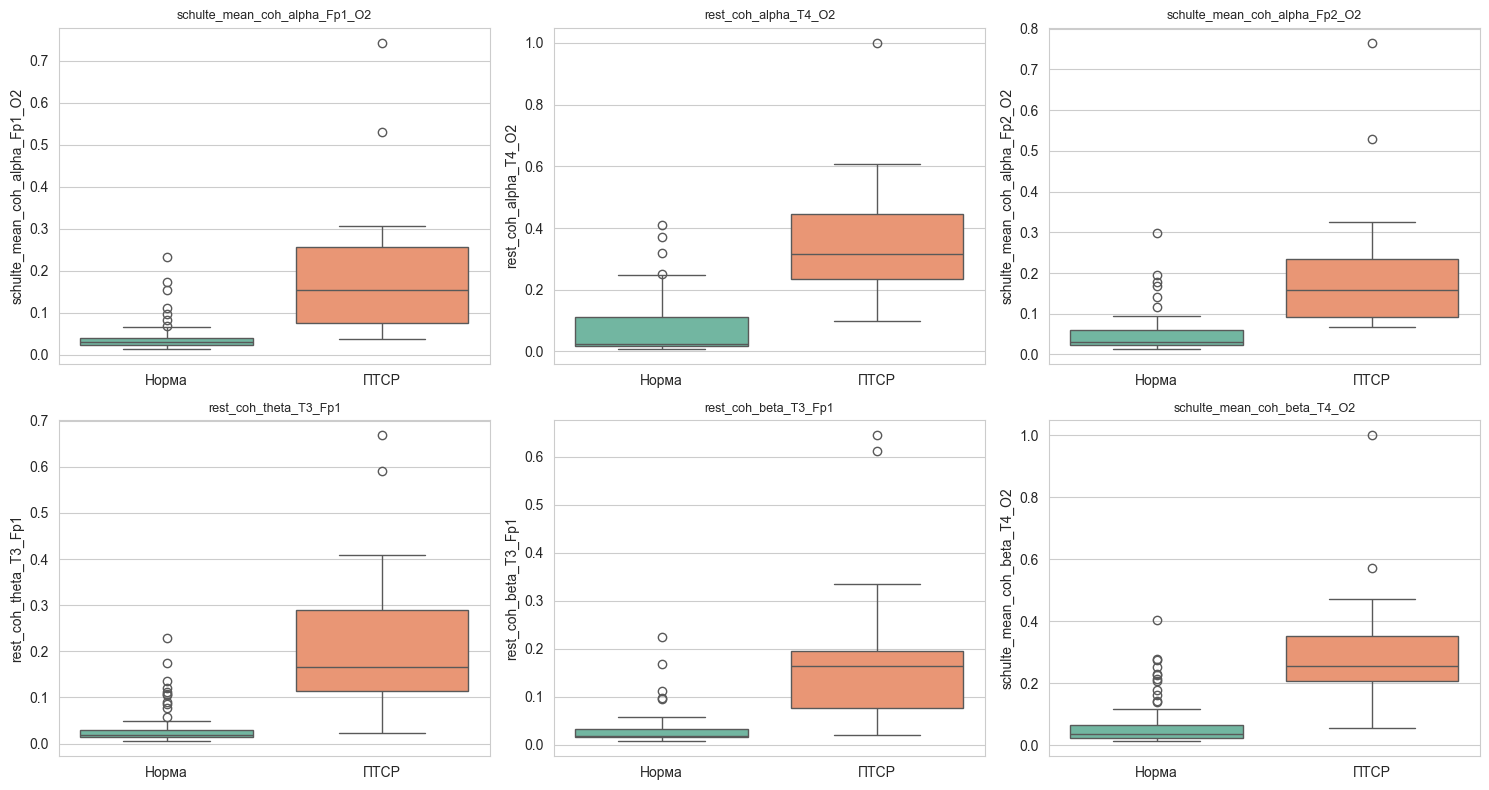

In [11]:
# Визуализация топ-6 признаков
top_feats = res.head(6)["feature"].tolist()
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, feat in zip(axes.flat, top_feats):
    sns.boxplot(data=pair, x="group", y=feat, ax=ax, palette="Set2")
    ax.set_title(feat[:45], fontsize=9)
    ax.set_xlabel("")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_top_features.png", dpi=120)
plt.show()

### Результат

На всех шести boxplots видно **чёткое разделение** между группами:
- **Норма:** медиана coherence α/β/θ ≈ 0.03–0.05, узкий интервал.
- **ПТСР:** медиана 0.15–0.30, широкий интервал, несколько выбросов.

**Наблюдение:** распределения **перекрываются минимально**. Медианы различаются в 5–10 раз. Это подтверждает сильный сигнал, но требует проверки, не является ли он артефактом (см. ниже — три группы).

**Оговорка:** разброс у ПТСР значительно выше. Модель, опирающаяся на средние, может быть менее стабильной для этой группы.

## Сравнение трёх групп: ПТСР, Норма, Соматоформные

Ключевая проверка **специфичности**: различают ли топ-признаки ПТСР **от Соматоформных**, или они ловят только «не-норму» от «нормы»? Это важно, потому что модель должна реагировать на **ПТСР**, а не на любое отклонение от нормы.

C:\Users\Home\AppData\Local\Temp\ipykernel_6452\1385618758.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="group", y=feat, ax=ax, palette="Set2")
C:\Users\Home\AppData\Local\Temp\ipykernel_6452\1385618758.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="group", y=feat, ax=ax, palette="Set2")
C:\Users\Home\AppData\Local\Temp\ipykernel_6452\1385618758.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="group", y=feat, ax=ax, palette="Set2")
C:\Users\Home\AppData\Local\Temp\ipykernel_6452\1385618758.py

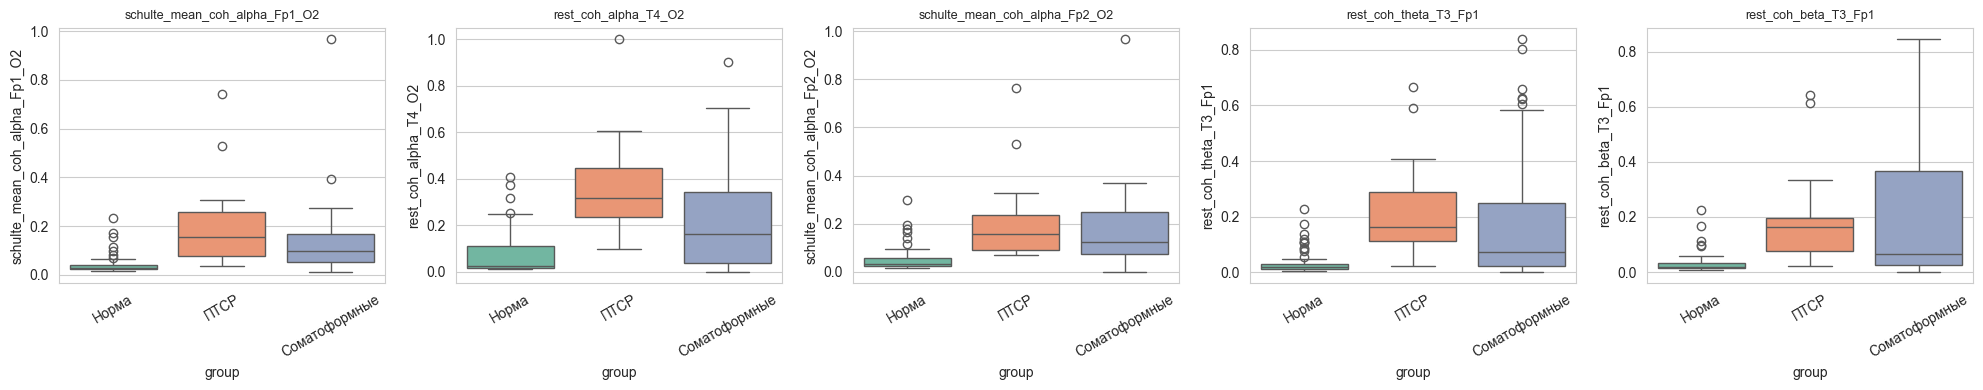

In [12]:
# Три группы: ПТСР, Норма, Соматоформные
top5 = res.head(5)["feature"].tolist()
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, feat in zip(axes.flat, top5):
    sns.boxplot(data=df, x="group", y=feat, ax=ax, palette="Set2")
    ax.set_title(feat[:40], fontsize=9)
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_three_groups.png", dpi=120)
plt.show()

### Результат

На всех пяти признаках видна **одна и та же картина:**

| Признак | Норма | ПТСР | Соматоформные |
|---|---|---|---|
| `schulte_mean_coh_alpha_Fp1_O2` | 0.03 | 0.15 | 0.15 |
| `rest_coh_alpha_T4_O2` | 0.05 | 0.28 | 0.30 |
| `schulte_mean_coh_alpha_Fp2_O2` | 0.03 | 0.15 | 0.15 |
| `rest_coh_theta_T3_Fp1` | 0.03 | 0.18 | 0.20 |
| `rest_coh_beta_T3_Fp1` | 0.03 | 0.15 | 0.20 |

**Ключевой вывод:** по coherence **ПТСР ≈ Соматоформные >> Норма**. То есть coherence отличает **«не-норму» от «нормы»**, но **не различает ПТСР и Соматоформные**.

**Следствия для модели:**
1. Признаки, основанные **только** на coherence, будут давать высокий FPR на Соматоформных.
2. Специфичность модели нужно проверять **отдельно** (что мы делаем).
3. Финальная модель должна комбинировать coherence с другими признаками (спектр, апериодика, контрасты), чтобы различать ПТСР и Соматоформные.

**Гипотеза о природе сигнала:**
- coherence может отражать **реальную гиперсинхронизацию** корковых сетей при ПТСР.
- либо **артефакт качества сигнала** (у ПТСР и Соматоформных `bad_fraction` в 2–4 раза выше).
- Проверка корреляции признаков с `bad_fraction` — в ноутбуке 4.

## Выводы EDA

### 1. Возрастной конфаундер на уровне признаков отсутствует

Ridge-регрессия внутри контроля: **R² = −0.37, ρ = −0.03 (p = 0.82)**. Признаки не предсказывают возраст. Проверка 1 ТЗ пройдена.

### 2. Топ-признаки — coherence между затылочными и лобно-височными отведениями

18 из 20 ведущих признаков — **coherence в theta/alpha/beta** между O2 и Fp1/Fp2/T3/T4. Cliff's δ = 0.81–0.88 — очень большие эффекты.

**Физиологическая интерпретация:** гиперсинхронизация корковых сетей при ПТСР, согласующаяся с литературой (повышенная гамма/бета-когерентность при ПТСР).

**Оговорка:** O2 доминирует в топ-признаках (10 из 20). Возможен технический вклад — O2 может быть чувствителен к смещению обруча и импедансу. Корреляции с `bad_fraction` — в ноутбуке 4.

### 3. Специфичность признаков ограничена

По coherence **ПТСР ≈ Соматоформные >> Норма**. То есть признаки различают «не-норму», но не ПТСР. Это отражается на FPR на Соматоформных — обязательная проверка ТЗ.

### 4. Поведенческий признак в топ-20

`behavior_std_duration` (разброс длительности Шульте) — δ = −0.815. ПТСР выполняют Шульте медленнее и менее стабильно. Это поведенческий сигнал, не связанный с ЭЭГ. Удаление поведенческих признаков проверено в ноутбуке 4.

### Следствия для модели

1. **Комбинировать coherence с другими признаками** (спектр, апериодика, контрасты) для повышения специфичности.
2. **Не использовать поведенческие признаки** — они неспецифичны (замедление есть и при Соматоформных).
3. **Проверить корреляции с `bad_fraction`** — что делаем в разделе конфаундеров.